<a href="https://colab.research.google.com/github/AbhinayM02/EDAV-Course-End-Project/blob/main/Shopping_Festival_Sales_Pattern_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Shopping Festival Sales Pattern Analysis

## EDAV Course-End Project

**Objective:** Analyze shopping festival sales data using exploratory data analysis, statistical methods, data manipulation, time-series analysis, and visualizations to identify sales trends and patterns.

**Dataset:** Shopping Festival Sales Dataset


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
# Load dataset
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/sales_data.csv")

In [ ]:

df.head()


,order_id,order_date,customer_id,gender,age,region,city,category,product,unit_price,quantity,discount,sales,profit,channel,payment_method,rating
0,ORD100001,2023-01-01,C00543,Male,43,North,Jaipur,Beauty,Sunscreen,557,4,0.00,2228.0,164.59,Store,UPI,5.0
1,ORD100002,2023-01-01,C01001,Female,40,South,Bengaluru,Home & Kitchen,Table Lamp,851,2,0.05,1616.9,160.72,Online,Cash on Delivery,4.0
2,ORD100003,2023-01-01,C00224,Female,34,East,Bhubaneswar,Books & Stationery,Exam Guide,544,1,0.10,489.6,75.61,Mobile App,UPI,4.0
3,ORD100004,2023-01-01,C01603,Male,27,East,Bhubaneswar,Home & Kitchen,Bedsheet Set,916,5,0.00,4580.0,439.43,Mobile App,UPI,4.0
4,ORD100005,2023-01-01,C00248,Male,21,West,Mumbai,Beauty,Sunscreen,574,1,0.05,545.3,116.65,Store,UPI,NaN


In [ ]:

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of rows: 20000
Number of columns: 17


In [ ]:

print(df.select_dtypes(include=np.number).columns.tolist())


['age', 'unit_price', 'quantity', 'discount', 'sales', 'profit', 'rating']


CO1 — Creating NumPy Arrays

Aim
To create NumPy arrays from numerical data in the shopping festival dataset and understand how NumPy stores and processes values efficiently.

In [ ]:

# Creating NumPy arrays from sales data

sales_array = np.array(df["sales"])
quantity_array = np.array(df["quantity"])
profit_array = np.array(df["profit"])

print("Sales Array:", sales_array[:5])
print("Quantity Array:", quantity_array[:5])
print("Profit Array:", profit_array[:5])

print("\nType of array:", type(sales_array))
print("Total sales records:", sales_array.size)


Sales Array: [2228.  1616.9  489.6 4580.   545.3]
Quantity Array: [4 2 1 5 1]
Profit Array: [164.59 160.72  75.61 439.43 116.65]

Type of array: <class 'numpy.ndarray'>
Total sales records: 20000


In [ ]:

# Check array dimensions and shape

print("Sales array dimensions:", sales_array.ndim)
print("Sales array shape:", sales_array.shape)
print("Sales array size:", sales_array.size)

# Create a 2D array using sales and profit
sales_profit_array = np.array(df[["sales", "profit"]])

print("\nSales-Profit array shape:", sales_profit_array.shape)
print("Sales-Profit array dimensions:", sales_profit_array.ndim)


Sales array dimensions: 1
Sales array shape: (20000,)
Sales array size: 20000

Sales-Profit array shape: (20000, 2)
Sales-Profit array dimensions: 2


In [ ]:

# Access individual elements using indexing

print("First sale:", sales_array[0])
print("Second sale:", sales_array[1])
print("Third sale:", sales_array[2])

print("\nFirst order profit:", profit_array[0])
print("Fifth order quantity:", quantity_array[4])


First sale: 2228.0
Second sale: 1616.9
Third sale: 489.6

First order profit: 164.59
Fifth order quantity: 1


In [ ]:

# Extract a portion of the arrays

print("First five sales:", sales_array[:5])
print("Sales from index 5 to 9:", sales_array[5:10])
print("First ten profits:", profit_array[:10])

# Retrieve every second sales value
print("Every second sale:", sales_array[::2][:10])


First five sales: [2228.  1616.9  489.6 4580.   545.3]
Sales from index 5 to 9: [  736.    1304.    3209.    3590.05 75055.5 ]
First ten profits: [  164.59   160.72    75.61   439.43   116.65    52.06   221.29   513.96
   286.63 19186.1 ]
Every second sale: [ 2228.     489.6    545.3   1304.    3590.05  4394.    1351.5   5927.4
  1118.4  13104.  ]


In [ ]:

# Perform arithmetic operations

total_sales_profit = sales_array + profit_array
sales_difference = sales_array - profit_array
double_sales = sales_array * 2
half_sales = sales_array / 2

print("Sales + Profit:", total_sales_profit[:5])
print("Sales - Profit:", sales_difference[:5])
print("Double sales:", double_sales[:5])
print("Half sales:", half_sales[:5])


Sales + Profit: [2392.59 1777.62  565.21 5019.43  661.95]
Sales - Profit: [2063.41 1456.18  413.99 4140.57  428.65]
Double sales: [4456.  3233.8  979.2 9160.  1090.6]
Half sales: [1114.    808.45  244.8  2290.    272.65]


In [ ]:

# Aggregate calculations on sales data

print("Total Sales:", np.sum(sales_array))
print("Average Sales:", np.mean(sales_array))
print("Cumulative Sales of first 5 records:",
      np.cumsum(sales_array[:5]))
print("Total Profit:", np.sum(profit_array))


Total Sales: 222077816.75
Average Sales: 11103.8908375
Cumulative Sales of first 5 records: [2228.  3844.9 4334.5 8914.5 9459.8]
Total Profit: 34336143.58


In [ ]:

# Statistical analysis of sales

print("Minimum Sales:", np.min(sales_array))
print("Maximum Sales:", np.max(sales_array))
print("Median Sales:", np.median(sales_array))
print("Standard Deviation:", np.std(sales_array))


Minimum Sales: 100.1
Maximum Sales: 301935.0
Median Sales: 2128.0
Standard Deviation: 32356.02099737077


In [ ]:

# Reshape the first 12 sales records

sales_12 = sales_array[:12]
reshaped_sales = sales_12.reshape(3, 4)

print("Original Array:")
print(sales_12)

print("\nReshaped Array (3 rows, 4 columns):")
print(reshaped_sales)

print("\nNew Shape:", reshaped_sales.shape)


Original Array:
[ 2228.    1616.9    489.6   4580.     545.3    736.    1304.    3209.
  3590.05 75055.5   4394.    8252.  ]

Reshaped Array (3 rows, 4 columns):
[[ 2228.    1616.9    489.6   4580.  ]
 [  545.3    736.    1304.    3209.  ]
 [ 3590.05 75055.5   4394.    8252.  ]]

New Shape: (3, 4)


CO2 — Pandas Data Manipulation, Analysis and Summarization

Objective: Perform data manipulation, analysis, and summarization on structured data using Pandas data structures and functionalities.

In [ ]:

# Create a Pandas Series from the sales column

sales_series = pd.Series(df["sales"])

print("Sales Series:")
print(sales_series.head())

print("\nData type:", type(sales_series))
print("Number of elements:", sales_series.size)


Sales Series:
0    2228.0
1    1616.9
2     489.6
3    4580.0
4     545.3
Name: sales, dtype: float64

Data type: <class 'pandas.core.series.Series'>
Number of elements: 20000


In [ ]:

# Create a DataFrame with selected columns

sales_df = df[["order_id", "category", "quantity", "sales", "profit"]]

print("Sales DataFrame:")
display(sales_df.head())

print("\nDataFrame shape:", sales_df.shape)


Sales DataFrame:


,order_id,category,quantity,sales,profit
0,ORD100001,Beauty,4,2228.0,164.59
1,ORD100002,Home & Kitchen,2,1616.9,160.72
2,ORD100003,Books & Stationery,1,489.6,75.61
3,ORD100004,Home & Kitchen,5,4580.0,439.43
4,ORD100005,Beauty,1,545.3,116.65



DataFrame shape: (20000, 5)


In [ ]:

# Display all column names

print("Dataset Columns:")
print(df.columns.tolist())

print("\nTotal Columns:", len(df.columns))


Dataset Columns:
['order_id', 'order_date', 'customer_id', 'gender', 'age', 'region', 'city', 'category', 'product', 'unit_price', 'quantity', 'discount', 'sales', 'profit', 'channel', 'payment_method', 'rating']

Total Columns: 17


In [ ]:

# Display the data types of all columns

print("Column Data Types:")
print(df.dtypes)


Column Data Types:
order_id           object
order_date         object
customer_id        object
gender             object
age                 int64
region             object
city               object
category           object
product            object
unit_price          int64
quantity            int64
discount          float64
sales             float64
profit            float64
channel            object
payment_method     object
rating            float64
dtype: object


In [ ]:

# Generate descriptive statistics

print("Statistical Summary:")
display(df.describe())


Statistical Summary:


,age,unit_price,quantity,discount,sales,profit,rating
count,20000.000000,20000.000000,20000.00000,20000.000000,20000.000000,20000.000000,19800.000000
mean,41.550600,5318.760050,2.24070,0.061780,11103.890837,1716.807179,3.870556
std,13.904169,12745.262927,1.40544,0.079938,32356.829928,5677.073726,1.121248
min,18.000000,134.000000,1.00000,0.000000,100.100000,-14749.630000,1.000000
25%,30.000000,515.000000,1.00000,0.000000,902.000000,101.840000,3.000000
50%,41.000000,1281.500000,2.00000,0.050000,2128.000000,288.420000,4.000000
75%,54.000000,2735.000000,3.00000,0.100000,5456.850000,835.327500,5.000000
max,65.000000,60496.000000,5.00000,0.300000,301935.000000,88059.090000,5.000000


In [ ]:

# Select specific columns

selected_columns = df[["category", "quantity", "sales", "profit"]]

display(selected_columns.head(10))


,category,quantity,sales,profit
0,Beauty,4,2228.00,164.59
1,Home & Kitchen,2,1616.90,160.72
2,Books & Stationery,1,489.60,75.61
3,Home & Kitchen,5,4580.00,439.43
4,Beauty,1,545.30,116.65
5,Books & Stationery,4,736.00,52.06
6,Beauty,1,1304.00,221.29
7,Clothing,1,3209.00,513.96
8,Home & Kitchen,1,3590.05,286.63
9,Electronics,5,75055.50,19186.10


In [ ]:

# Select rows using integer positions

print("First row:")
display(df.iloc[0])

print("First five rows:")
display(df.iloc[0:5])

print("Rows 1 to 5, columns 0 to 3:")
display(df.iloc[1:6, 0:4])


First row:


,0
order_id,ORD100001
order_date,2023-01-01
customer_id,C00543
gender,Male
age,43
region,North
city,Jaipur
category,Beauty
product,Sunscreen
unit_price,557


First five rows:


,order_id,order_date,customer_id,gender,age,region,city,category,product,unit_price,quantity,discount,sales,profit,channel,payment_method,rating
0,ORD100001,2023-01-01,C00543,Male,43,North,Jaipur,Beauty,Sunscreen,557,4,0.00,2228.0,164.59,Store,UPI,5.0
1,ORD100002,2023-01-01,C01001,Female,40,South,Bengaluru,Home & Kitchen,Table Lamp,851,2,0.05,1616.9,160.72,Online,Cash on Delivery,4.0
2,ORD100003,2023-01-01,C00224,Female,34,East,Bhubaneswar,Books & Stationery,Exam Guide,544,1,0.10,489.6,75.61,Mobile App,UPI,4.0
3,ORD100004,2023-01-01,C01603,Male,27,East,Bhubaneswar,Home & Kitchen,Bedsheet Set,916,5,0.00,4580.0,439.43,Mobile App,UPI,4.0
4,ORD100005,2023-01-01,C00248,Male,21,West,Mumbai,Beauty,Sunscreen,574,1,0.05,545.3,116.65,Store,UPI,NaN


Rows 1 to 5, columns 0 to 3:


,order_id,order_date,customer_id,gender
1,ORD100002,2023-01-01,C01001,Female
2,ORD100003,2023-01-01,C00224,Female
3,ORD100004,2023-01-01,C01603,Male
4,ORD100005,2023-01-01,C00248,Male
5,ORD100006,2023-01-01,C00921,Male


In [ ]:

# Filter orders with sales greater than the average

average_sales = df["sales"].mean()

high_sales = df[df["sales"] > average_sales]

print("Average Sales:", average_sales)
print("Orders above average sales:", len(high_sales))

display(high_sales.head(10))


Average Sales: 11103.8908375
Orders above average sales: 2948


,order_id,order_date,customer_id,gender,age,region,city,category,product,unit_price,quantity,discount,sales,profit,channel,payment_method,rating
9,ORD100010,2023-01-01,C03354,Female,39,West,Ahmedabad,Electronics,Smartphone,16679,5,0.10,75055.50,19186.10,Online,Net Banking,5.0
17,ORD100018,2023-01-01,C00565,Male,24,North,Lucknow,Electronics,Laptop,51299,1,0.00,51299.00,14559.82,Online,UPI,5.0
18,ORD100019,2023-01-02,C02555,Male,37,West,Ahmedabad,Electronics,Smartphone,16380,1,0.20,13104.00,1879.38,Online,Debit Card,4.0
19,ORD100020,2023-01-02,C01636,Female,41,North,Delhi,Electronics,Smartphone,16319,2,0.05,31006.10,6659.91,Online,UPI,5.0
32,ORD100033,2023-01-02,C02004,Male,24,North,Lucknow,Electronics,Smartphone,15027,1,0.15,12772.95,2786.38,Mobile App,UPI,3.0
33,ORD100034,2023-01-02,C02671,Male,60,North,Jaipur,Electronics,Smartphone,17524,3,0.00,52572.00,10799.98,Mobile App,UPI,4.0
42,ORD100043,2023-01-03,C03614,Female,22,South,Kochi,Electronics,Laptop,53429,1,0.15,45414.65,314.86,Online,Cash on Delivery,4.0
57,ORD100058,2023-01-05,C03221,Male,39,North,Jaipur,Clothing,Sneakers,2501,5,0.00,12505.00,2179.24,Online,Cash on Delivery,4.0
58,ORD100059,2023-01-05,C01728,Male,18,South,Hyderabad,Electronics,Smartphone,15002,1,0.00,15002.00,2153.46,Store,Credit Card,4.0
60,ORD100061,2023-01-05,C00849,Female,56,South,Hyderabad,Electronics,Smartphone,17118,1,0.10,15406.20,3237.28,Store,Net Banking,4.0


In [ ]:

# Sort orders by sales in descending order

sorted_sales = df.sort_values(by="sales", ascending=False)

print("Top 10 orders by sales:")
display(sorted_sales.head(10))

# Sort orders by profit in ascending order
sorted_profit = df.sort_values(by="profit", ascending=True)

print("10 orders with the lowest profit:")
display(sorted_profit.head(10))


Top 10 orders by sales:


,order_id,order_date,customer_id,gender,age,region,city,category,product,unit_price,quantity,discount,sales,profit,channel,payment_method,rating
9744,ORD109745,2024-09-10,C02724,Female,41,East,Guwahati,Electronics,Laptop,60387,5,0.0,301935.0,62959.97,Online,UPI,5.0
5568,ORD105569,2023-12-19,C00825,Female,51,South,Kochi,Electronics,Laptop,60298,5,0.0,301490.0,88059.09,Online,Cash on Delivery,5.0
2831,ORD102832,2023-07-30,C02246,Female,23,North,Lucknow,Electronics,Laptop,60220,5,0.0,301100.0,20903.36,Online,UPI,5.0
17762,ORD117763,2025-10-12,C03363,Male,33,North,Lucknow,Electronics,Laptop,59747,5,0.0,298735.0,33031.08,Online,Credit Card,4.0
654,ORD100655,2023-02-20,C03928,Female,28,East,Kolkata,Electronics,Laptop,59628,5,0.0,298140.0,70910.29,Store,Credit Card,1.0
16821,ORD116822,2025-08-30,C00502,Female,37,West,Mumbai,Electronics,Laptop,59577,5,0.0,297885.0,37886.75,Store,UPI,4.0
4509,ORD104510,2023-11-01,C00335,Male,65,South,Hyderabad,Electronics,Laptop,59455,5,0.0,297275.0,41030.16,Online,UPI,4.0
5964,ORD105965,2024-01-12,C03432,Male,54,South,Bengaluru,Electronics,Laptop,59085,5,0.0,295425.0,57276.63,Online,Net Banking,1.0
17927,ORD117928,2025-10-18,C01397,Female,61,North,Chandigarh,Electronics,Laptop,59084,5,0.0,295420.0,17968.86,Online,Cash on Delivery,5.0
4021,ORD104022,2023-10-11,C02144,Male,25,South,Bengaluru,Electronics,Laptop,58536,5,0.0,292680.0,78449.44,Mobile App,Credit Card,5.0


10 orders with the lowest profit:


,order_id,order_date,customer_id,gender,age,region,city,category,product,unit_price,quantity,discount,sales,profit,channel,payment_method,rating
13256,ORD113257,2025-02-15,C01847,Female,38,North,Jaipur,Electronics,Laptop,54099,5,0.3,189346.5,-14749.63,Mobile App,UPI,2.0
9741,ORD109742,2024-09-10,C02188,Male,40,South,Coimbatore,Electronics,Laptop,58839,4,0.3,164749.2,-10341.16,Mobile App,Net Banking,5.0
15245,ORD115246,2025-06-05,C01810,Female,51,East,Guwahati,Electronics,Laptop,49665,4,0.3,139062.0,-7841.30,Store,UPI,5.0
2818,ORD102819,2023-07-29,C00183,Male,63,West,Surat,Electronics,Laptop,51047,3,0.3,107198.7,-7303.93,Store,Credit Card,3.0
17362,ORD117363,2025-09-28,C03143,Female,34,South,Kochi,Electronics,Laptop,53625,4,0.3,150150.0,-6721.89,Store,UPI,5.0
6980,ORD106981,2024-03-16,C02465,Male,62,South,Chennai,Electronics,Laptop,58213,5,0.2,232852.0,-5802.19,Store,UPI,5.0
15673,ORD115674,2025-06-29,C02062,Male,31,North,Delhi,Electronics,Laptop,58354,2,0.3,81695.6,-5424.06,Online,Debit Card,4.0
7843,ORD107844,2024-05-13,C03872,Female,51,South,Coimbatore,Electronics,Laptop,57739,2,0.3,80834.6,-5161.74,Online,Cash on Delivery,4.0
14004,ORD114005,2025-03-30,C02533,Female,48,North,Lucknow,Electronics,Laptop,53686,2,0.3,75160.4,-4891.74,Online,Credit Card,4.0
7145,ORD107146,2024-03-27,C00147,Female,22,West,Ahmedabad,Electronics,Laptop,58898,4,0.2,188473.6,-4271.09,Store,Net Banking,2.0


In [ ]:

# Check for duplicate records

duplicate_rows = df.duplicated()

print("Total duplicate rows:", duplicate_rows.sum())

print("\nDuplicate records:")
display(df[duplicate_rows].head(10))


Total duplicate rows: 0

Duplicate records:


,order_id,order_date,customer_id,gender,age,region,city,category,product,unit_price,quantity,discount,sales,profit,channel,payment_method,rating


CO3 — Data Cleaning and Wrangling

Objective: Apply Pandas techniques to handle missing data, transform and categorize values, perform hierarchical indexing, merge and reshape datasets, and prepare data for meaningful analysis.

In [ ]:

# Identify missing values in the dataset

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values in dataset:")
print(df.isnull().sum().sum())


Missing values in each column:
order_id            0
order_date          0
customer_id         0
gender              0
age                 0
region              0
city                0
category            0
product             0
unit_price          0
quantity            0
discount            0
sales               0
profit              0
channel             0
payment_method      0
rating            200
dtype: int64

Total missing values in dataset:
200


In [ ]:

# Count duplicate records
print("Duplicate records:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())


Duplicate records: 0
Shape after removing duplicates: (20000, 17)
Remaining duplicates: 0


In [ ]:

# Display available payment methods
print("Payment methods:")
print(df["payment_method"].unique())

# Create a copy for replacement
df["payment_method"] = df["payment_method"].replace(
    {"Credit Card": "Card", "Debit Card": "Card"}
)

print("\nUpdated payment methods:")
print(df["payment_method"].unique())


Payment methods:
['UPI' 'Cash on Delivery' 'Net Banking' 'Debit Card' 'Credit Card']

Updated payment methods:
['UPI' 'Cash on Delivery' 'Net Banking' 'Card']


In [ ]:

# Create a new column with sales rounded to the nearest integer

df["rounded_sales"] = df["sales"].apply(round)

print("Original and transformed sales:")
display(df[["sales", "rounded_sales"]].head(10))



Original and transformed sales:


,sales,rounded_sales
0,2228.00,2228
1,1616.90,1617
2,489.60,490
3,4580.00,4580
4,545.30,545
5,736.00,736
6,1304.00,1304
7,3209.00,3209
8,3590.05,3590
9,75055.50,75056


In [ ]:

# Divide sales into three categories

df["sales_category"] = pd.cut(
    df["sales"],
    bins=3,
    labels=["Low", "Medium", "High"]
)

print("Sales categories:")
display(df[["sales", "sales_category"]].head(10))

print("\nCount in each category:")
print(df["sales_category"].value_counts())


Sales categories:


,sales,sales_category
0,2228.00,Low
1,1616.90,Low
2,489.60,Low
3,4580.00,Low
4,545.30,Low
5,736.00,Low
6,1304.00,Low
7,3209.00,Low
8,3590.05,Low
9,75055.50,Low



Count in each category:
sales_category
Low       19474
Medium      320
High        206
Name: count, dtype: int64


In [ ]:

# Rename selected columns

df = df.rename(columns={
    "sales": "sales_amount",
    "profit": "profit_amount",
    "quantity": "items_quantity"
})

print("Updated column names:")
print(df.columns.tolist())

display(df.head())


Updated column names:
['order_id', 'order_date', 'customer_id', 'gender', 'age', 'region', 'city', 'category', 'product', 'unit_price', 'items_quantity', 'discount', 'sales_amount', 'profit_amount', 'channel', 'payment_method', 'rating', 'rounded_sales', 'sales_category']


,order_id,order_date,customer_id,gender,age,region,city,category,product,unit_price,items_quantity,discount,sales_amount,profit_amount,channel,payment_method,rating,rounded_sales,sales_category
0,ORD100001,2023-01-01,C00543,Male,43,North,Jaipur,Beauty,Sunscreen,557,4,0.00,2228.0,164.59,Store,UPI,5.0,2228,Low
1,ORD100002,2023-01-01,C01001,Female,40,South,Bengaluru,Home & Kitchen,Table Lamp,851,2,0.05,1616.9,160.72,Online,Cash on Delivery,4.0,1617,Low
2,ORD100003,2023-01-01,C00224,Female,34,East,Bhubaneswar,Books & Stationery,Exam Guide,544,1,0.10,489.6,75.61,Mobile App,UPI,4.0,490,Low
3,ORD100004,2023-01-01,C01603,Male,27,East,Bhubaneswar,Home & Kitchen,Bedsheet Set,916,5,0.00,4580.0,439.43,Mobile App,UPI,4.0,4580,Low
4,ORD100005,2023-01-01,C00248,Male,21,West,Mumbai,Beauty,Sunscreen,574,1,0.05,545.3,116.65,Store,UPI,4.0,545,Low


CO4 — Group Operations and Time Series Analysis
Objective: Summarize and analyze sales using group operations, and handle time series data through date conversion, time-based selection, resampling, and frequency changes.

In [ ]:

# Group sales by product category

category_sales = df.groupby("category")["sales_amount"].sum()

print("Total Sales by Category:")
display(category_sales.sort_values(ascending=False))


Total Sales by Category:


,sales_amount
category,
Electronics,1.868937e+08
Clothing,1.635561e+07
Home & Kitchen,1.222447e+07
Beauty,3.829043e+06
Books & Stationery,2.774972e+06


In [ ]:

# Calculate multiple statistics by category

category_summary = df.groupby("category").agg(
    total_sales=("sales_amount", "sum"),
    average_sales=("sales_amount", "mean"),
    total_profit=("profit_amount", "sum"),
    total_quantity=("items_quantity", "sum")
)

print("Category-wise Summary:")
display(category_summary.round(2))


Category-wise Summary:


,total_sales,average_sales,total_profit,total_quantity
category,,,,
Beauty,3.829043e+06,1231.20,596301.06,6972
Books & Stationery,2.774972e+06,1065.66,451220.43,5819
Clothing,1.635561e+07,3455.65,2531359.47,10454
Electronics,1.868937e+08,33379.84,28821643.94,12624
Home & Kitchen,1.222447e+07,3091.67,1935618.68,8945


In [ ]:

# Calculate regional sales performance

region_summary = df.groupby("region").agg(
    total_sales=("sales_amount", "sum"),
    total_profit=("profit_amount", "sum"),
    number_of_records=("order_id", "count")
)

print("Regional Sales Performance:")
display(region_summary.sort_values(
    by="total_sales", ascending=False
).round(2))


Regional Sales Performance:


,total_sales,total_profit,number_of_records
region,,,
South,70069874.35,10727611.79,6347
North,58178511.80,9188104.42,5070
West,56941521.00,8923886.81,5237
East,36887909.60,5496540.56,3346


In [ ]:

# Extract date components

df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month
df["day"] = df["order_date"].dt.day

print("Extracted date components:")
display(df[["order_date", "year", "month", "day"]].head(10))


Extracted date components:


,order_date,year,month,day
0,2023-01-01,2023,1,1
1,2023-01-01,2023,1,1
2,2023-01-01,2023,1,1
3,2023-01-01,2023,1,1
4,2023-01-01,2023,1,1
5,2023-01-01,2023,1,1
6,2023-01-01,2023,1,1
7,2023-01-01,2023,1,1
8,2023-01-01,2023,1,1
9,2023-01-01,2023,1,1


In [ ]:

# Calculate monthly total sales

date_df = df.dropna(subset=["order_date"]).copy()
date_df = date_df.set_index("order_date")

monthly_sales = date_df["sales_amount"].resample("MS").sum()

print("Monthly Sales:")
display(monthly_sales)

print("\nHighest monthly sales:")
print(monthly_sales.idxmax(), ":", monthly_sales.max())


Monthly Sales:


,sales_amount
order_date,
2023-01-01,4956202.65
2023-02-01,4198555.75
2023-03-01,3523055.30
2023-04-01,3616623.65
2023-05-01,4621089.20
2023-06-01,5393519.45
2023-07-01,5704215.45
2023-08-01,5142226.80
2023-09-01,4697751.10



Highest monthly sales:
2025-11-01 00:00:00 : 10636182.95


In [ ]:

# Compare monthly and quarterly sales

monthly_sales = date_df["sales_amount"].resample("MS").sum()
quarterly_sales = date_df["sales_amount"].resample("QS").sum()

print("Monthly Sales:")
display(monthly_sales)

print("\nQuarterly Sales:")
display(quarterly_sales)

print("\nTotal monthly sales:", monthly_sales.sum())
print("Total quarterly sales:", quarterly_sales.sum())


Monthly Sales:


,sales_amount
order_date,
2023-01-01,4956202.65
2023-02-01,4198555.75
2023-03-01,3523055.30
2023-04-01,3616623.65
2023-05-01,4621089.20
2023-06-01,5393519.45
2023-07-01,5704215.45
2023-08-01,5142226.80
2023-09-01,4697751.10



Quarterly Sales:


,sales_amount
order_date,
2023-01-01,12677813.70
2023-04-01,13631232.30
2023-07-01,15544193.35
2023-10-01,24308829.40
2024-01-01,14190363.00
2024-04-01,14099208.25
2024-07-01,15412907.60
2024-10-01,25710092.80
2025-01-01,19048008.95



Total monthly sales: 222077816.75
Total quarterly sales: 222077816.75


CO5 — Data Visualization using Matplotlib and Seaborn

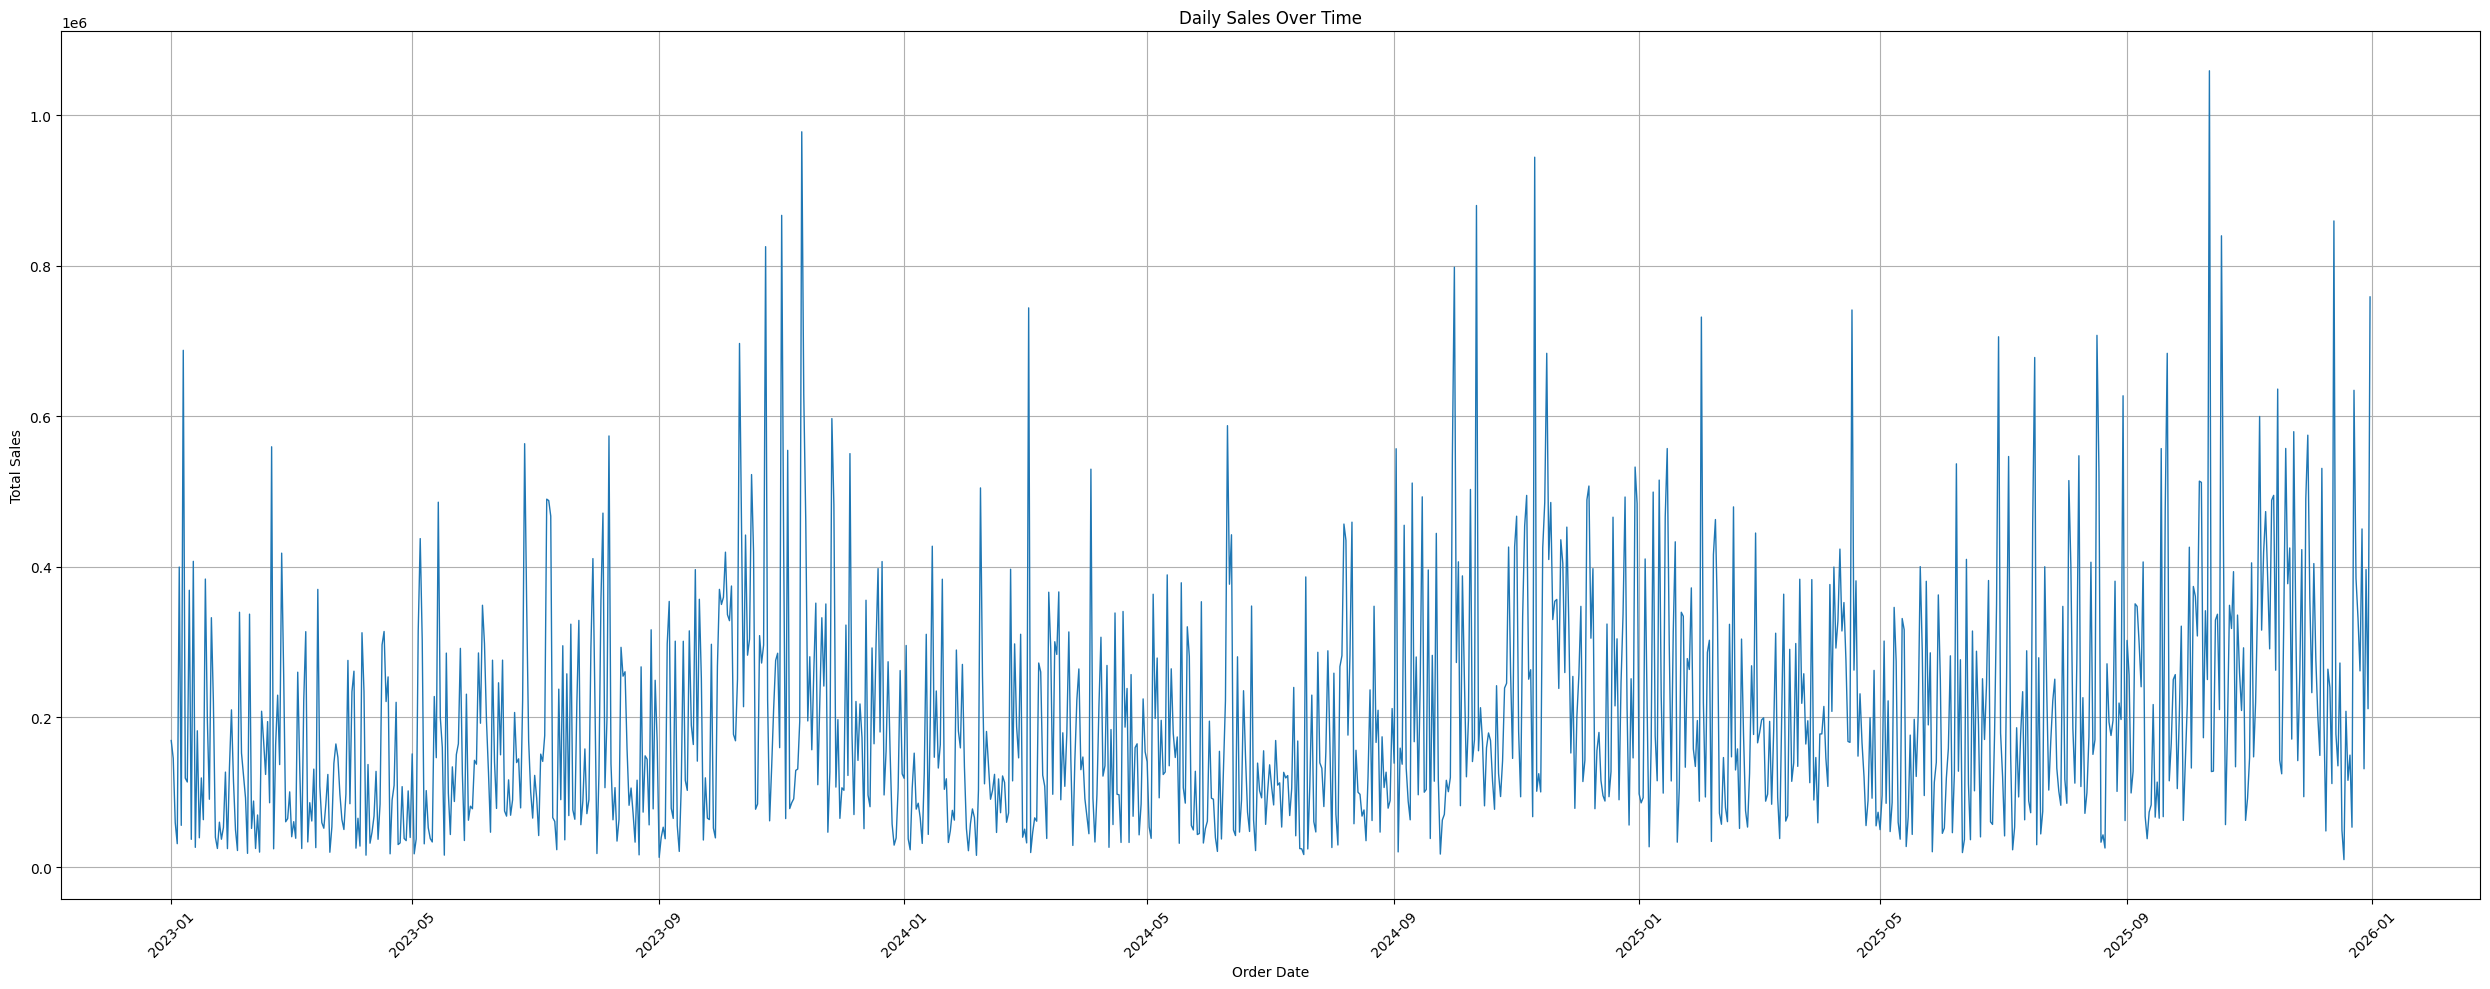

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")

daily_sales = (
    df.dropna(subset=["order_date"])
      .groupby("order_date")["sales_amount"]
      .sum()
      .sort_index()
)

plt.figure(figsize=(25,10))
plt.plot(daily_sales.index, daily_sales.values, linestyle="-", linewidth=1)

plt.title("Daily Sales Over Time")
plt.xlabel("Order Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


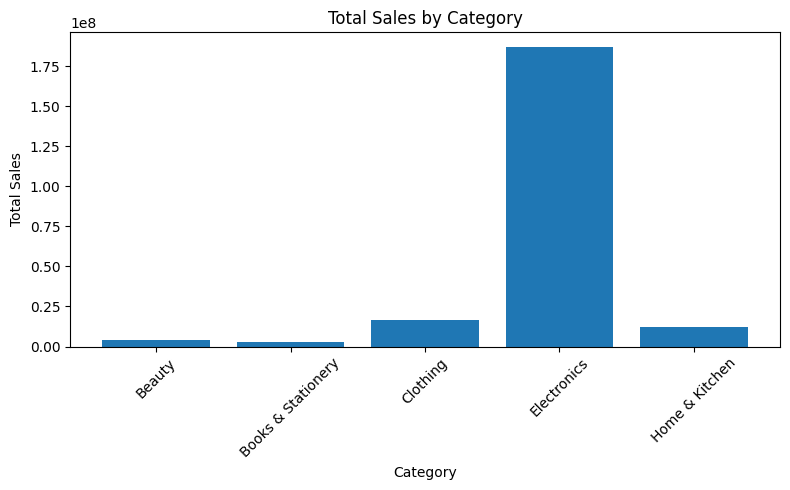

In [ ]:

import matplotlib.pyplot as plt

category_sales = df.groupby("category")["sales_amount"].sum()

plt.figure(figsize=(8, 5))
plt.bar(category_sales.index, category_sales.values)

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


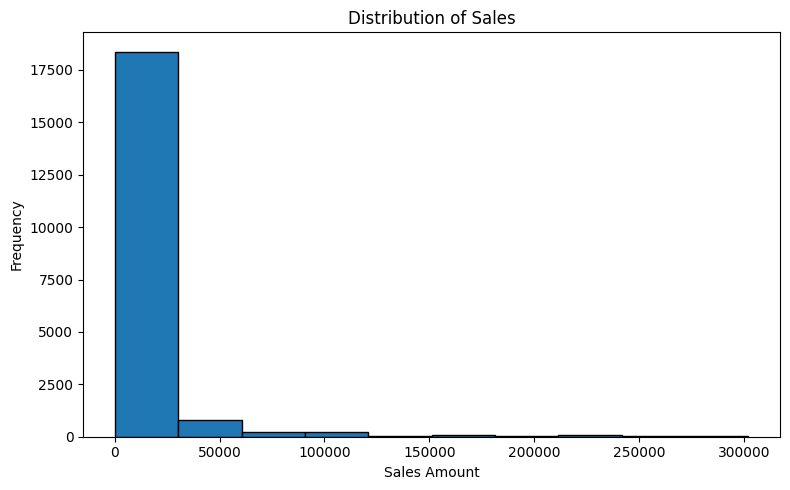

In [ ]:

import matplotlib.pyplot as plt

sales = df["sales_amount"].dropna()

plt.figure(figsize=(8, 5))
plt.hist(sales, bins=10, edgecolor="black")

plt.title("Distribution of Sales")
plt.xlabel("Sales Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


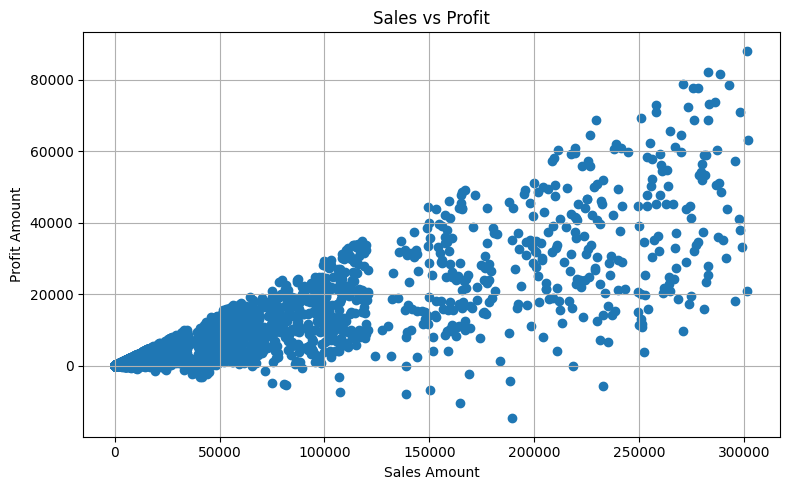

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(df["sales_amount"], df["profit_amount"])

plt.title("Sales vs Profit")
plt.xlabel("Sales Amount")
plt.ylabel("Profit Amount")
plt.grid(True)
plt.tight_layout()
plt.show()


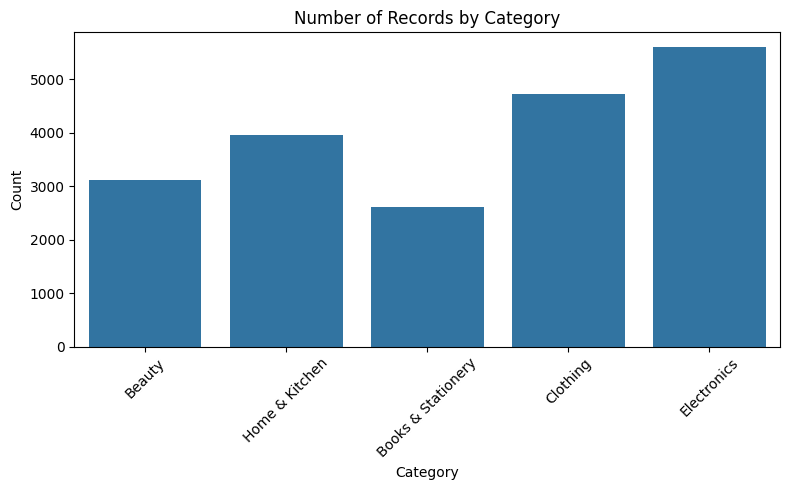

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="category")

plt.title("Number of Records by Category")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


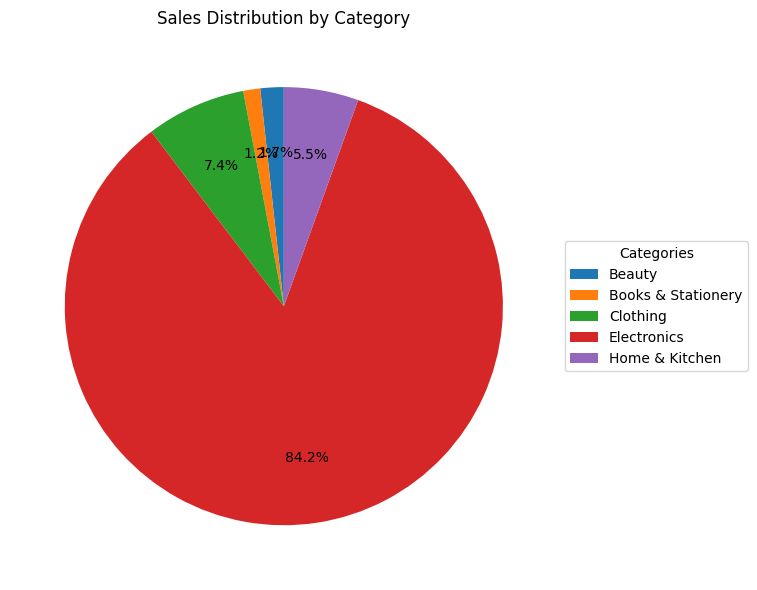

In [ ]:

import matplotlib.pyplot as plt

category_sales = df.groupby("category")["sales_amount"].sum()

plt.figure(figsize=(10, 6))

plt.pie(
    category_sales,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.7
)

plt.legend(
    category_sales.index,
    title="Categories",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.title("Sales Distribution by Category")
plt.tight_layout()
plt.show()


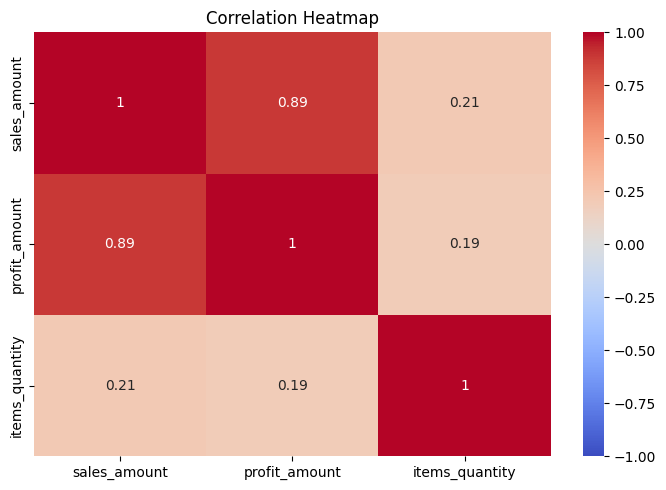

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns
num_df = df[[
    "sales_amount",
    "profit_amount",
    "items_quantity"
]]

# Calculate correlation
corr = num_df.corr()

# Draw heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


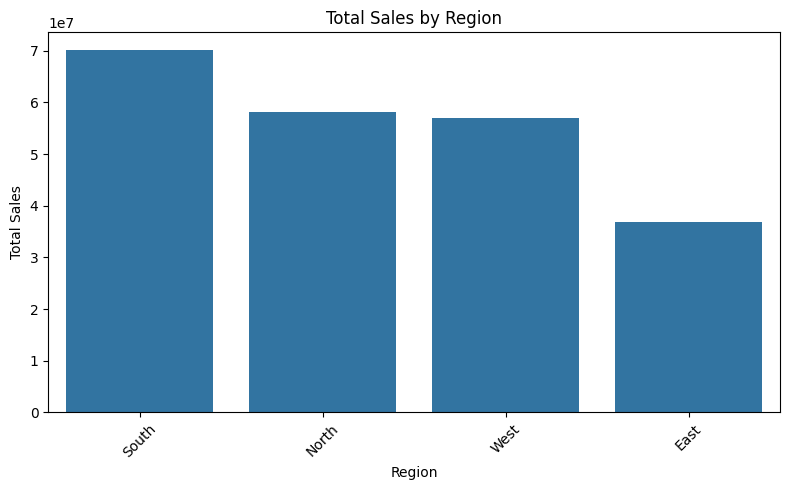

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate regional sales
region_sales = (
    df.groupby("region", as_index=False)["sales_amount"]
      .sum()
      .sort_values("sales_amount", ascending=False)
)

# Draw bar chart
plt.figure(figsize=(8, 5))
sns.barplot(data=region_sales, x="region", y="sales_amount")

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Conclusion

The Shopping Festival Sales Pattern Analysis project was carried out to understand sales trends, product category performance, and regional sales patterns.

## Key Findings
- **Product categories** showed differences in their contributions to total sales.
- **Regional analysis** helped compare sales performance across different regions.
- **Time-series analysis** helped examine sales changes over monthly and quarterly periods.
- **Sales and profit analysis** helped explore relationships between sales, profit, and quantity sold.

## Overall Insight

The analysis demonstrates how Python libraries can help identify sales patterns and support data-driven decisions. These findings can help businesses improve inventory management, product promotions, and sales planning.